# EN3160 Assignment 2 - Questions 1 and 2

This notebook contains only the answers and stored outputs for Questions 1 and 2.

In [11]:
import os, glob
import numpy as np
import cv2 as cv
import matplotlib.pyplot as plt
from matplotlib.patches import Circle
from scipy import ndimage
from scipy.optimize import minimize

IMG_DIR = 'a2images'
plt.rcParams['figure.dpi'] = 110

def show(img_bgr, title=None, ax=None):
    ax = ax or plt.gca()
    ax.imshow(cv.cvtColor(img_bgr, cv.COLOR_BGR2RGB))
    ax.set_title(title); ax.axis('off')

---
# Question 1 — Blob detection with the Laplacian of Gaussian (LoG)

**Method.** A circular blob of radius $r$ gives its strongest *scale-normalised* LoG response, $\sigma^2\nabla^2 G_\sigma * I$, at $\sigma = r/\sqrt{2}$.
So we

1. build a scale space by evaluating the scale-normalised LoG at $\sigma_i = \sigma_0 k^i$,
2. find local extrema in the 3-D $(\sigma, y, x)$ volume (26-neighbourhood) above a threshold,
3. report each extremum as a circle with centre $(x,y)$ and radius $r=\sqrt{2}\,\sigma$,
4. suppress overlapping circles, keeping the *larger* one (so a head is reported once, not once per petal).

**Pre-processing (why a plain grey-scale image is not enough).** On the grey-scale image the *clouds* are the brightest, largest blobs and the sunflower heads are ring-shaped (yellow petals around a dark seed disc), so a raw LoG mostly fires on clouds and on individual petals. Since the goal is to find sunflowers, we first build a "yellowness" map $Y=\mathrm{clip}\big((R+G)/2-B\big)$, which is high on petals and ≈ 0 on sky, clouds and leaves, threshold it, and fill the holes (the dark seed discs) so each head becomes a solid bright disc. The LoG scale-space is then computed on this map. `cv2.HoughCircles` is not used.

image size (H, W): (360, 360)


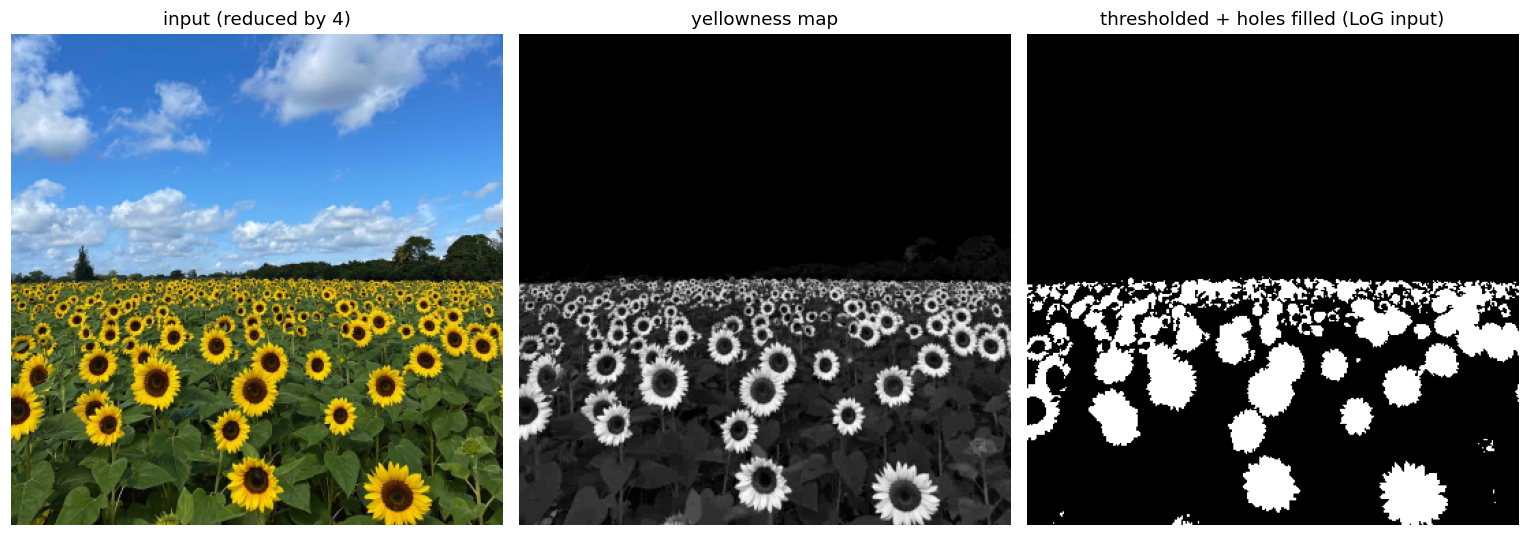

sigma range: 2.00 ... 21.40  (14 levels, k=1.2)
corresponding radii r = sqrt(2)*sigma: 2.8 ... 30.3 px


In [2]:
im = cv.imread(f'{IMG_DIR}/the_berry_farms_sunflower_field.jpeg', cv.IMREAD_REDUCED_COLOR_4)
assert im is not None, 'sunflower image not found'
print('image size (H, W):', im.shape[:2])

# ---- pre-processing: yellow petal map, holes (dark seed discs) filled ----
f = im.astype(np.float32) / 255.0
B_, G_, R_ = f[..., 0], f[..., 1], f[..., 2]
yellow = np.clip(0.5 * (R_ + G_) - B_, 0, 1)
petal_mask = ndimage.binary_fill_holes(yellow > 0.35)
signal = petal_mask.astype(np.float32)

fig, axs = plt.subplots(1, 3, figsize=(14, 5))
show(im, 'input (reduced by 4)', ax=axs[0])
axs[1].imshow(yellow, cmap='gray'); axs[1].set_title('yellowness map'); axs[1].axis('off')
axs[2].imshow(signal, cmap='gray'); axs[2].set_title('thresholded + holes filled (LoG input)'); axs[2].axis('off')
plt.tight_layout(); plt.show()

# ---- scale space parameters ----
SIGMA_0  = 2.0      # smallest sigma
K        = 1.2      # multiplicative step between scales
N_LEVELS = 14       # -> sigma from 2.0 to ~21.4
sigmas = SIGMA_0 * K ** np.arange(N_LEVELS)
print(f'sigma range: {sigmas[0]:.2f} ... {sigmas[-1]:.2f}  ({N_LEVELS} levels, k={K})')
print(f'corresponding radii r = sqrt(2)*sigma: {np.sqrt(2)*sigmas[0]:.1f} ... {np.sqrt(2)*sigmas[-1]:.1f} px')

def log_scale_space(img, sigmas):
    # Scale-normalised LoG: sigma^2 * Laplacian(Gaussian_sigma * I).
    stack = []
    for s in sigmas:
        g = cv.GaussianBlur(img, (0, 0), s, borderType=cv.BORDER_REPLICATE)
        lap = cv.Laplacian(g, cv.CV_32F, ksize=1)
        stack.append(s ** 2 * lap)
    return np.stack(stack, axis=0)             # (n_sigma, H, W)

L = log_scale_space(signal, sigmas)
R = -L          # bright blobs  -> LoG is negative at the centre -> maximise -LoG

number of blobs detected: 77


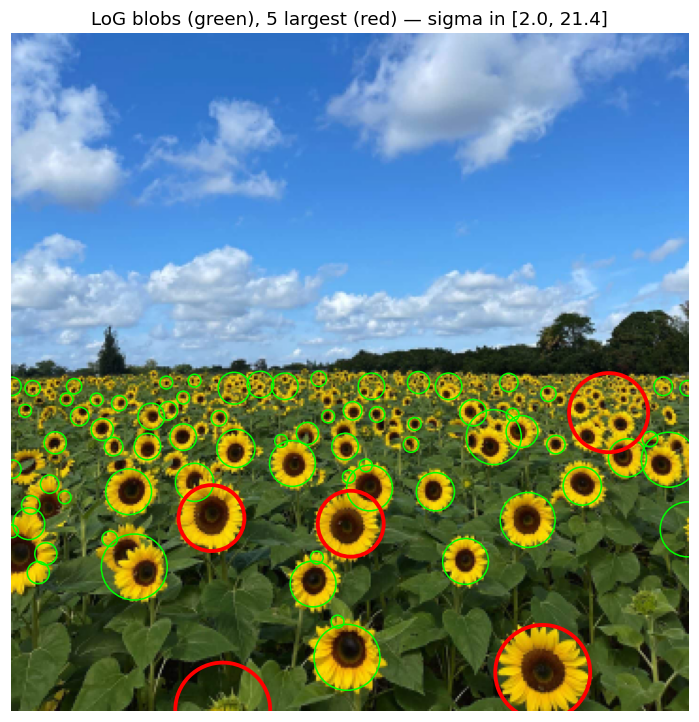

rank      x      y   radius   sigma  response
   1    282    339    25.22   17.83     0.662
   2    112    359    25.22   17.83     4.345
   3    317    201    21.02   14.86     0.400
   4    106    257    17.51   12.38     0.577
   5    180    260    17.51   12.38     0.518


In [3]:
def detect_blobs(R, sigmas, thresh=0.20, overlap_frac=1.0):
    # 3x3x3 non-maximum suppression in (sigma, y, x)
    local_max = ndimage.maximum_filter(R, size=(3, 3, 3), mode='nearest')
    mask = (R == local_max) & (R > thresh)
    # ignore the first/last scale: an extremum there is not a true scale-space extremum
    mask[0] = False; mask[-1] = False
    si, ys, xs = np.nonzero(mask)
    blobs = [(x, y, np.sqrt(2) * sigmas[i], sigmas[i], R[i, y, x]) for i, y, x in zip(si, ys, xs)]
    blobs.sort(key=lambda b: -b[2])              # largest first: a head beats its petals

    kept = []
    for b in blobs:                              # drop circles whose centre lies inside a larger kept circle
        ok = True
        for q in kept:
            d = np.hypot(b[0] - q[0], b[1] - q[1])
            if d < overlap_frac * max(b[2], q[2]):
                ok = False; break
        if ok: kept.append(b)
    return kept

blobs = detect_blobs(R, sigmas, thresh=0.20)
print('number of blobs detected:', len(blobs))

def draw_blobs(img, blobs, highlight=(), color='lime', hcolor='red'):
    fig, ax = plt.subplots(figsize=(8, 8))
    show(img, ax=ax)
    for b in blobs:
        ax.add_patch(Circle((b[0], b[1]), b[2], fill=False, color=color, lw=1))
    for b in highlight:
        ax.add_patch(Circle((b[0], b[1]), b[2], fill=False, color=hcolor, lw=2.5))
    return fig, ax

N_LARGEST = 5
largest = sorted(blobs, key=lambda b: -b[2])[:N_LARGEST]
fig, ax = draw_blobs(im, blobs, highlight=largest)
ax.set_title(f'LoG blobs (green), {N_LARGEST} largest (red) — sigma in [{sigmas[0]:.1f}, {sigmas[-1]:.1f}]')
plt.show()

print(f'{"rank":>4} {"x":>6} {"y":>6} {"radius":>8} {"sigma":>7} {"response":>9}')
for i, b in enumerate(largest, 1):
    print(f'{i:>4} {b[0]:>6d} {b[1]:>6d} {b[2]:>8.2f} {b[3]:>7.2f} {b[4]:>9.3f}')

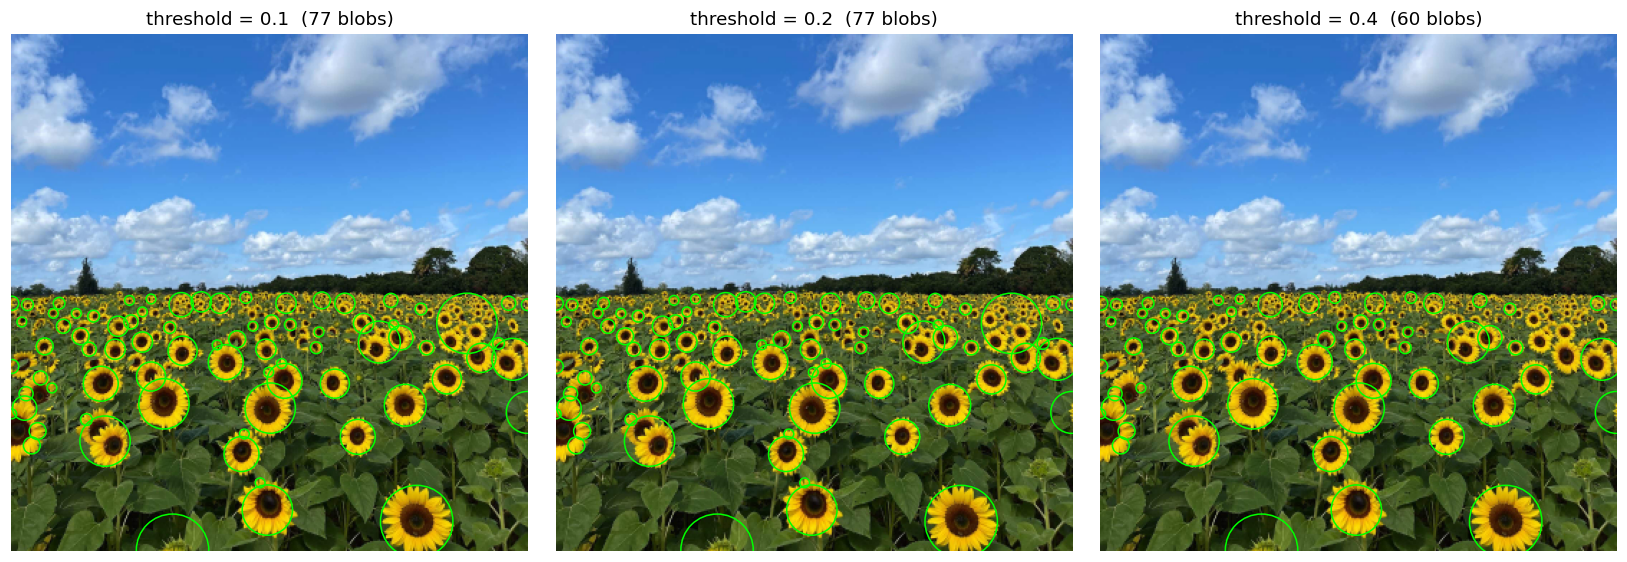

In [4]:
# Sensitivity to the threshold (useful for the discussion)
fig, axs = plt.subplots(1, 3, figsize=(15, 5))
for ax, th in zip(axs, [0.10, 0.20, 0.40]):
    bl = detect_blobs(R, sigmas, thresh=th)
    show(im, ax=ax)
    for b in bl: ax.add_patch(Circle((b[0], b[1]), b[2], fill=False, color='lime', lw=1))
    ax.set_title(f'threshold = {th}  ({len(bl)} blobs)')
plt.tight_layout(); plt.show()

### Q1 — Results and discussion

* **σ range used:** σ = 2.0 to ≈ 21.4 (14 levels, k = 1.2), i.e. radii of about 2.8 – 30 px on the 4× reduced 360 × 360 image. The upper limit was chosen from the biggest flower head (radius ≈ 25–28 px). Larger σ values only create spurious blobs formed by *clusters* of small distant flowers.
* **Largest circles** (centre $(x,y)$, radius $r=\sqrt2\sigma$, σ) are tabulated in the output above; copy the five rows into the report. They sit on the big, close-up flower heads in the bottom half of the image (e.g. the one near the bottom right at about (282, 339), r ≈ 25 px, σ ≈ 17.8).
* **Observations.** Detected radii shrink towards the horizon because distant flowers are smaller (perspective) — this is exactly what the scale-space extremum picks up. A higher threshold keeps only high-contrast heads; a lower one adds small spurious blobs. Flowers cut by the image border, and heads that overlap each other, are the main failure cases; one of the "largest" circles is actually a clump of several small distant flowers merged into one blob at a coarser scale.
* **Pre-processing matters.** On plain grey-scale the strongest and largest LoG blobs are the *clouds*, and each sunflower head (bright petals around a dark seed disc) breaks into a ring of petal blobs. Using the yellow map + hole filling makes each head a solid disc, so the head-scale extremum is found and the method behaves as intended.

---
# Question 2 — Line and circle fitting with RANSAC

We generate the noisy point set (Listing 1; 50 points on a circle with centre (2, 3), radius 10, plus 50 points on the line $y=-x+2$).

**Models**
* **Line:** $ax+by=d$ with $\|[a,b]^\top\|=1$. A sample of 2 points gives the unit normal $[a,b]=[-\Delta y,\Delta x]/\|\cdot\|$ and $d=[a,b]\cdot p_1$. Error = normal distance $|ax_i+by_i-d|$.
* **Circle:** centre $(c_x,c_y)$, radius $r$. A sample of 3 points gives the circle through them (solve $x^2+y^2+Dx+Ey+F=0$). Error = radial distance $|\sqrt{(x_i-c_x)^2+(y_i-c_y)^2}-r|$.
* The final model after RANSAC is **re-estimated from all inliers** using `scipy.optimize.minimize` (line: SLSQP with the equality constraint $a^2+b^2=1$; circle: least squares on the radial error).

**Choosing thresholds.** The line points have Gaussian noise σ = 1 in $y$; since the line has slope −1, the noise in the *normal* direction is σ/√2 ≈ 0.71, so a threshold of 1.5 (≈ 2.1σ) keeps ≈ 96 % of true inliers. The circle noise is σ = r/16 = 0.625 radially, so a threshold of 1.5 ≈ 2.4σ keeps ≈ 98 % of them. The minimum consensus is 30 points: the line has 50 true points and the circle has 50, so 30 is comfortably above what a random model can collect and comfortably below the true count.

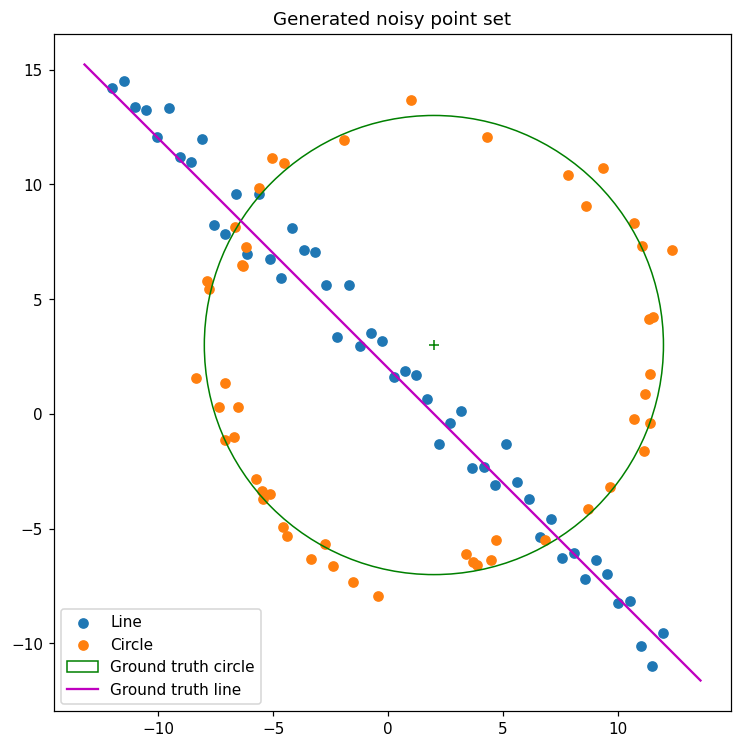

In [5]:
# ---------- Listing 1: noisy point set (line + circle) ----------
np.random.seed(0)
N = 100
half_n = N // 2
r = 10
x0_gt, y0_gt = 2, 3                          # circle centre
s = r / 16
t = np.random.uniform(0, 2 * np.pi, half_n)
n = s * np.random.randn(half_n)
x, y = x0_gt + (r + n) * np.cos(t), y0_gt + (r + n) * np.sin(t)
X_circ = np.hstack((x.reshape(half_n, 1), y.reshape(half_n, 1)))

s = 1.
m, b = -1, 2
x = np.linspace(-12, 12, half_n)
y = m * x + b + s * np.random.randn(half_n)
X_line = np.hstack((x.reshape(half_n, 1), y.reshape(half_n, 1)))

X = np.vstack((X_circ, X_line))              # all points  (first 50: circle, last 50: line)
is_circle_gt = np.r_[np.ones(half_n, bool), np.zeros(half_n, bool)]

fig, ax = plt.subplots(1, 1, figsize=(8, 8))
ax.scatter(X_line[:, 0], X_line[:, 1], label='Line')
ax.scatter(X_circ[:, 0], X_circ[:, 1], label='Circle')
ax.add_patch(plt.Circle((x0_gt, y0_gt), r, color='g', fill=False, label='Ground truth circle'))
ax.plot((x0_gt), (y0_gt), '+', color='g')
x_min, x_max = ax.get_xlim()
x_ = np.array([x_min, x_max])
ax.plot(x_, m * x_ + b, color='m', label='Ground truth line')
ax.set_aspect('equal'); ax.legend(); plt.title('Generated noisy point set'); plt.show()

In [6]:
rng = np.random.default_rng(1)

# ======================= LINE =======================
def line_from_sample(p1, p2):
    # returns (a, b, d) with a^2 + b^2 = 1
    dx, dy = p2 - p1
    nrm = np.hypot(dx, dy)
    if nrm < 1e-9: return None
    a, b_ = -dy / nrm, dx / nrm
    return np.array([a, b_, a * p1[0] + b_ * p1[1]])

def line_error(P, model):
    a, b_, d = model
    return np.abs(P[:, 0] * a + P[:, 1] * b_ - d)       # normal distance (since ||[a,b]|| = 1)

def refine_line(P, model0):
    # minimise sum (a x + b y - d)^2   subject to  a^2 + b^2 = 1
    cost = lambda p: np.sum((P[:, 0] * p[0] + P[:, 1] * p[1] - p[2]) ** 2)
    cons = {'type': 'eq', 'fun': lambda p: p[0] ** 2 + p[1] ** 2 - 1}
    res = minimize(cost, model0, constraints=cons, method='SLSQP')
    return res.x

def ransac_line(P, thresh, min_inliers, n_iter=2000):
    best = None
    for _ in range(n_iter):
        idx = rng.choice(len(P), 2, replace=False)
        mdl = line_from_sample(P[idx[0]], P[idx[1]])
        if mdl is None: continue
        err = line_error(P, mdl)
        inl = err < thresh
        cnt = inl.sum()
        if cnt < min_inliers: continue
        score = (cnt, -err[inl].sum())                    # more inliers, then lower error
        if best is None or score > best['score']:
            best = dict(score=score, sample_idx=idx, sample_model=mdl, inliers=inl)
    if best is None: raise RuntimeError('RANSAC (line) found no model with enough consensus')
    best['model'] = refine_line(P[best['inliers']], best['sample_model'])
    return best

# ======================= CIRCLE =======================
def circle_from_sample(p1, p2, p3):
    A = np.array([[p[0], p[1], 1.0] for p in (p1, p2, p3)])
    rhs = -np.array([p[0] ** 2 + p[1] ** 2 for p in (p1, p2, p3)])
    if abs(np.linalg.det(A)) < 1e-9: return None          # collinear points
    D, E, F = np.linalg.solve(A, rhs)
    cx, cy = -D / 2, -E / 2
    r2 = cx ** 2 + cy ** 2 - F
    if r2 <= 0: return None
    return np.array([cx, cy, np.sqrt(r2)])

def circle_error(P, model):
    cx, cy, rr = model
    return np.abs(np.hypot(P[:, 0] - cx, P[:, 1] - cy) - rr)   # radial error

def refine_circle(P, model0):
    cost = lambda p: np.sum((np.hypot(P[:, 0] - p[0], P[:, 1] - p[1]) - p[2]) ** 2)
    return minimize(cost, model0, method='Nelder-Mead',
                    options=dict(xatol=1e-8, fatol=1e-10, maxiter=5000)).x

def ransac_circle(P, thresh, min_inliers, n_iter=3000):
    best = None
    for _ in range(n_iter):
        idx = rng.choice(len(P), 3, replace=False)
        mdl = circle_from_sample(*P[idx])
        if mdl is None: continue
        err = circle_error(P, mdl)
        inl = err < thresh
        cnt = inl.sum()
        if cnt < min_inliers: continue
        score = (cnt, -err[inl].sum())
        if best is None or score > best['score']:
            best = dict(score=score, sample_idx=idx, sample_model=mdl, inliers=inl)
    if best is None: raise RuntimeError('RANSAC (circle) found no model with enough consensus')
    best['model'] = refine_circle(P[best['inliers']], best['sample_model'])
    return best

### (a) Fit the line with RANSAC

In [7]:
LINE_THRESH, LINE_MIN = 1.5, 30
line_res = ransac_line(X, LINE_THRESH, LINE_MIN)
a_, b_, d_ = line_res['model']
print(f'RANSAC line:  a={a_:.4f}, b={b_:.4f}, d={d_:.4f},  ||[a,b]|| = {np.hypot(a_, b_):.6f}')
print(f'inliers: {line_res["inliers"].sum()}  (true line points captured: '
      f'{(line_res["inliers"] & ~is_circle_gt).sum()}/50, circle points absorbed: {(line_res["inliers"] & is_circle_gt).sum()})')
gt_n = np.array([1, 1]) / np.sqrt(2)                       # ground truth y = -x + 2  ->  x + y = 2
print(f'ground truth: normal=[{gt_n[0]:.4f}, {gt_n[1]:.4f}], d={2 / np.sqrt(2):.4f}   (sign of [a,b,d] is arbitrary)')

RANSAC line:  a=0.7181, b=0.6959, d=1.5222,  ||[a,b]|| = 1.000000
inliers: 56  (true line points captured: 50/50, circle points absorbed: 6)
ground truth: normal=[0.7071, 0.7071], d=1.4142   (sign of [a,b,d] is arbitrary)


### (b) Remove the line consensus, then fit the circle to the remnant

In [8]:
remnant_mask = ~line_res['inliers']
X_rem = X[remnant_mask]
print('points in remnant:', len(X_rem))

CIRC_THRESH, CIRC_MIN = 1.5, 30
circ_res = ransac_circle(X_rem, CIRC_THRESH, CIRC_MIN)
cx_, cy_, rr_ = circ_res['model']
print(f'RANSAC circle: centre=({cx_:.3f}, {cy_:.3f}), r={rr_:.3f}     (ground truth: centre=(2, 3), r=10)')
print('circle inliers:', circ_res['inliers'].sum())

points in remnant: 44
RANSAC circle: centre=(1.868, 3.067), r=9.949     (ground truth: centre=(2, 3), r=10)
circle inliers: 44


### (c) Combined plot

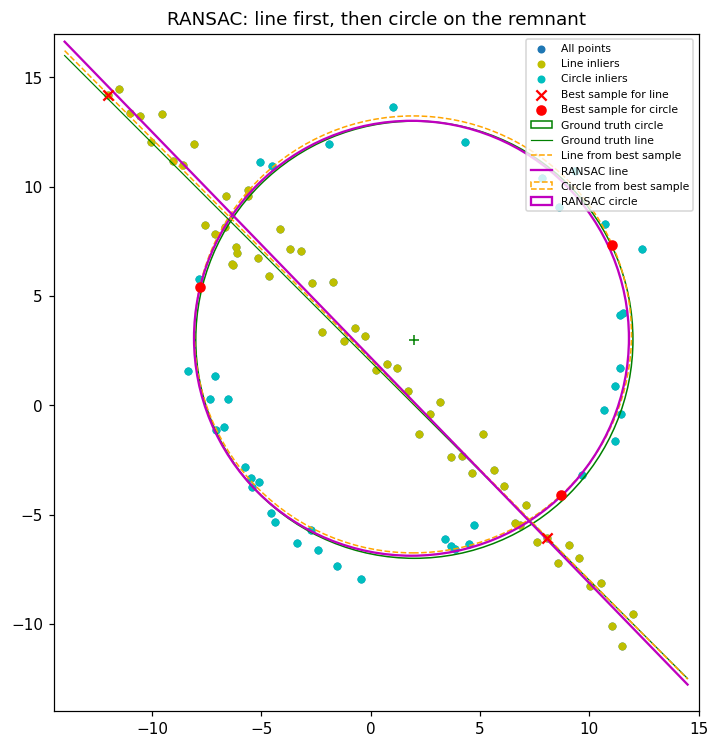

circle: centre error = 0.148, radius error = 0.051
circle points captured: 44 of 50 true circle points (some line points may remain in the remnant)


In [9]:
def plot_fit(X, line_res, circ_res, title, ax=None, remnant_mask=None):
    ax = ax or plt.subplots(figsize=(8, 8))[1]
    ax.scatter(X[:, 0], X[:, 1], s=18, c='tab:blue', label='All points')
    li = line_res['inliers']
    ax.scatter(X[li, 0], X[li, 1], s=18, c='y', label='Line inliers')
    Xr = X if remnant_mask is None else X[remnant_mask]
    ci = circ_res['inliers']
    ax.scatter(Xr[ci, 0], Xr[ci, 1], s=18, c='c', label='Circle inliers')
    sl = X[line_res['sample_idx']]
    ax.scatter(sl[:, 0], sl[:, 1], marker='x', c='r', s=45, label='Best sample for line', zorder=5)
    sc = Xr[circ_res['sample_idx']]
    ax.scatter(sc[:, 0], sc[:, 1], c='r', s=35, label='Best sample for circle', zorder=5)

    # ground truth
    ax.add_patch(plt.Circle((x0_gt, y0_gt), r, color='g', fill=False, label='Ground truth circle'))
    ax.plot(x0_gt, y0_gt, '+', color='g')
    xl = np.array([-14, 14.5])
    ax.plot(xl, m * xl + b, color='g', lw=0.8, label='Ground truth line')

    # line from the minimal sample, and best-fit line
    def draw_line(mdl, **kw):
        a, b_, d = mdl
        if abs(b_) > 1e-9: ax.plot(xl, (d - a * xl) / b_, **kw)
    draw_line(line_res['sample_model'], color='orange', ls='--', lw=1, label='Line from best sample')
    draw_line(line_res['model'], color='m', lw=1.5, label='RANSAC line')

    # circle from the minimal sample, and best-fit circle
    cs = circ_res['sample_model']; cb = circ_res['model']
    ax.add_patch(plt.Circle(cs[:2], cs[2], color='orange', fill=False, ls='--', lw=1, label='Circle from best sample'))
    ax.add_patch(plt.Circle(cb[:2], cb[2], color='m', fill=False, lw=1.5, label='RANSAC circle'))
    ax.set_xlim(-14.5, 15); ax.set_ylim(-14, 17); ax.set_aspect('equal')
    ax.legend(fontsize=7, loc='upper right'); ax.set_title(title)
    return ax

plot_fit(X, line_res, circ_res, 'RANSAC: line first, then circle on the remnant', remnant_mask=remnant_mask)
plt.show()

# Quantitative comparison with ground truth
print(f'circle: centre error = {np.hypot(cx_ - x0_gt, cy_ - y0_gt):.3f}, radius error = {abs(rr_ - r):.3f}')
print(f'circle points captured: {(circ_res["inliers"]).sum()} of 50 true circle points '
      f'(some line points may remain in the remnant)')

### (d) What happens if we fit the circle first?
We run the identical circle RANSAC (same threshold, same minimum consensus) on **all** 100 points, remove its inliers, and then fit the line to the remnant.

circle-first model: centre=(1.96, 2.88), r=9.83
  inliers: 60  | true circle points: 49/50 | line points absorbed: 11/50
  line fitted to the remnant afterwards: a=-0.723 b=-0.691 d=-1.660


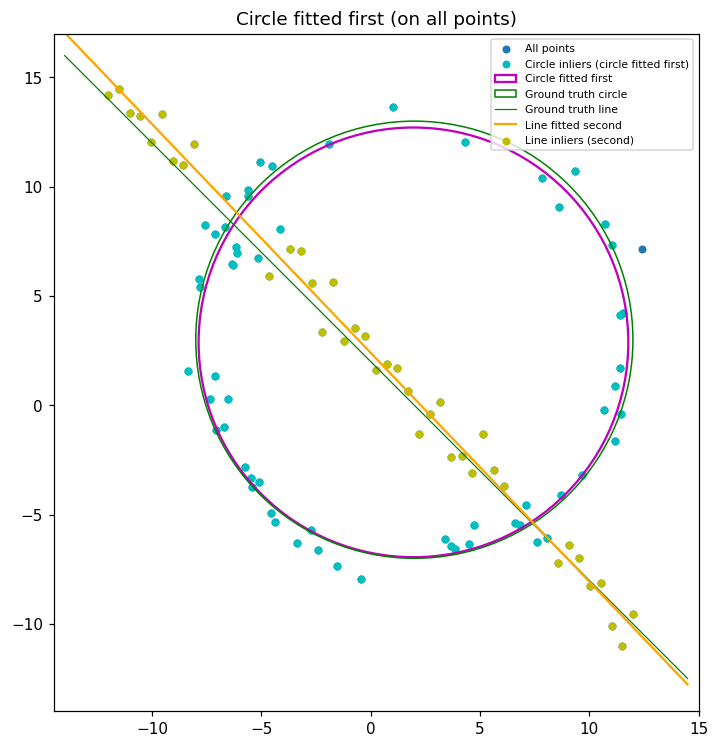

In [10]:
rng = np.random.default_rng(1)
try:
    circ_first = ransac_circle(X, CIRC_THRESH, CIRC_MIN)
    inl_c = circ_first['inliers']
    print('circle-first model: centre=(%.2f, %.2f), r=%.2f' % tuple(circ_first['model']))
    print(f'  inliers: {inl_c.sum()}  | true circle points: {(inl_c & is_circle_gt).sum()}/50 | line points absorbed: {(inl_c & ~is_circle_gt).sum()}/50')

    rem2 = ~inl_c
    line_second = ransac_line(X[rem2], LINE_THRESH, min(LINE_MIN, max(5, int(0.6 * (~is_circle_gt & rem2).sum()))))
    print('  line fitted to the remnant afterwards: a=%.3f b=%.3f d=%.3f' % tuple(line_second['model']))

    fig, ax = plt.subplots(figsize=(8, 8))
    ax.scatter(X[:, 0], X[:, 1], s=18, label='All points')
    ax.scatter(X[inl_c, 0], X[inl_c, 1], s=18, c='c', label='Circle inliers (circle fitted first)')
    ax.add_patch(plt.Circle(circ_first['model'][:2], circ_first['model'][2], color='m', fill=False, lw=1.5, label='Circle fitted first'))
    ax.add_patch(plt.Circle((x0_gt, y0_gt), r, color='g', fill=False, label='Ground truth circle'))
    xl = np.array([-14, 14.5]); ax.plot(xl, m * xl + b, color='g', lw=0.8, label='Ground truth line')
    a2, b2, d2 = line_second['model']
    ax.plot(xl, (d2 - a2 * xl) / b2, color='orange', lw=1.5, label='Line fitted second')
    Xr2 = X[rem2]; li2 = line_second['inliers']
    ax.scatter(Xr2[li2, 0], Xr2[li2, 1], s=18, c='y', label='Line inliers (second)')
    ax.set_xlim(-14.5, 15); ax.set_ylim(-14, 17); ax.set_aspect('equal'); ax.legend(fontsize=7, loc='upper right')
    ax.set_title('Circle fitted first (on all points)'); plt.show()
except RuntimeError as e:
    print('Circle-first RANSAC failed:', e)

### Q2 — Discussion

* **Line first (a–c):** the line points form a single thin, dense structure (50 of 100 points), so a 2-point minimal sample on the line gathers a large consensus and RANSAC finds it reliably. The re-estimated line (SLSQP with $\|[a,b]\|=1$) is close to the ground truth $x+y=2$. Its consensus also swallows the few circle points lying near where the line crosses the ring (printed above: all 50 true line points captured, a few circle points absorbed). The remnant then contains almost only circle points, and the circle RANSAC recovers a circle very close to the ground truth (centre (2, 3), radius 10; errors printed above).
* **Circle first (d):** the identical circle RANSAC on all 100 points still finds a reasonable circle in our run, because the ring is dense, but the process is inherently less well-conditioned: with 50 % outliers a random 3-point sample consists only of ring points with probability $(1/2)^3 = 12.5\,\%$, versus $(1/2)^2 = 25\,\%$ for a 2-point line sample. For $p=0.99$ this means $N=\ln(0.01)/\ln(1-w^s)\approx 35$ iterations instead of $\approx 16$ and a lower chance of a good hypothesis for a given iteration budget. More importantly, the circle's consensus band (±1.5 around a radius-10 circle) absorbs all the line points that cross the ring (11 of the 50 line points in our run). Those points are then removed from the data, the line is fitted to the reduced and biased remnant, and the resulting line (printed above) is a bit worse than when the line is fitted first. With other random seeds, noise levels or thresholds the circle can also lock onto a spurious large circle that mixes ring and line points.
* **Conclusion:** fit the model that is *cheapest and best supported by the data* first (the line: 2 DOF, a 2-point sample, a thin consensus band that removes few points of the other shape), then remove its inliers and fit the more complex model to what is left.